In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix
print("libraries imported sucessfully")


libraries imported sucessfully


In [51]:
df=sns.load_dataset("titanic")
print("shape : ",df.shape)
df.head()

shape :  (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


survived
0    549
1    342
Name: count, dtype: int64


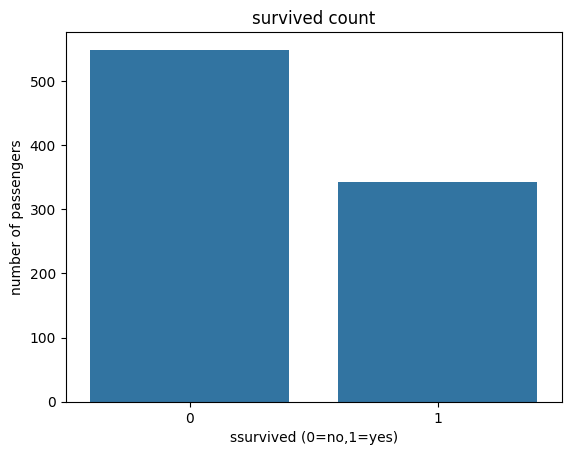

In [53]:
print(df["survived"].value_counts())
sns.countplot(data=df,x="survived")
plt.title("survived count")
plt.xlabel("ssurvived (0=no,1=yes)")
plt.ylabel("number of passengers")
plt.show()

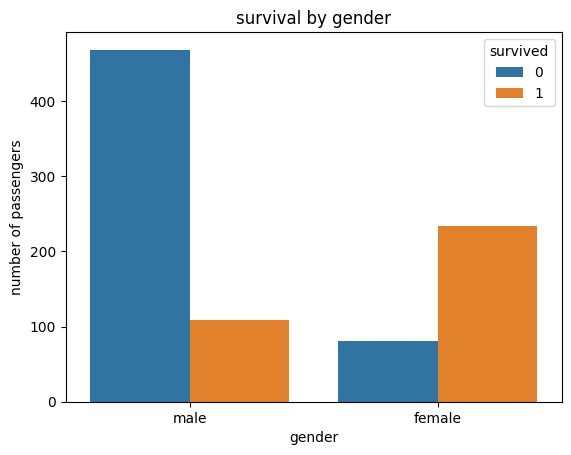

In [54]:
sns.countplot(data=df,x="sex",hue="survived")
plt.title("survival by gender")
plt.xlabel("gender")
plt.ylabel("number of passengers")
plt.show()

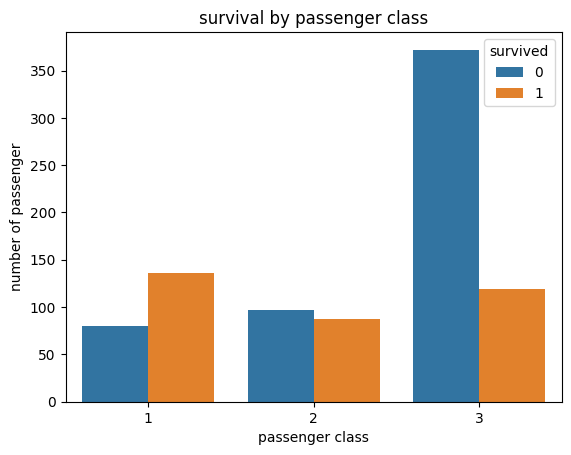

In [55]:
sns.countplot(data=df,x="pclass",hue="survived")
plt.title("survival by passenger class")
plt.xlabel("passenger class")
plt.ylabel("number of passenger")
plt.show()

In [56]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [57]:
features=["pclass","sex","age","sibsp","parch","fare","embarked"]
X=df[features].copy()
y=df["survived"].copy()
print("features")
print(X.head())
print("Target")
print(y.head())

features
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S
Target
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [58]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.20,random_state=42,stratify=y
)
print("training data : ",X_train.shape)
print("testing data : ",X_test.shape)

training data :  (712, 7)
testing data :  (179, 7)


In [59]:
age_median=X_train["age"].median()
X_train["age"]=X_train["age"].fillna(age_median)
X_test["age"]=X_test["age"].fillna(age_median)
embarked_mode=X_train["embarked"].mode()[0]
X_train["embarked"]=X_train["embarked"].fillna(embarked_mode)
X_test["embarked"]=X_test["embarked"].fillna(embarked_mode)
print("missing values after cleaning : ")
print(X_train.isnull().sum())

missing values after cleaning : 
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


In [ ]:
X_train=pd.get_dummies(X_train,columns=["sex","embarked"],drop_first=True)
X_test=pd.get_dummies(X_test,columns=["sex","embarked"],drop_first=True)

X_test=X_test.reindex(columns=X_train.columns,fill_value=0)
print("training columns : ")
print(X_train.columns.tolist())
print("Shape After Encoding : ")
print("X_train : ",X_train.shape)
print("X_test : ",X_test.shape)


training columns : 
['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']
/nShape After Encoding : 
X_train :  (712, 8)
X_test :  (179, 8)


In [ ]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print("Scaling Completed!")

Scaling Completed !


In [65]:
log_model=LogisticRegression(max_iter=100)
log_model.fit(X_train_scaled,y_train)
y_pred_log=log_model.predict(X_test_scaled)
log_accuracy=accuracy_score(y_test,y_pred_log)
print("logistic regression accuracy : ",round(log_accuracy,4))

logistic regression accuracy :  0.8045


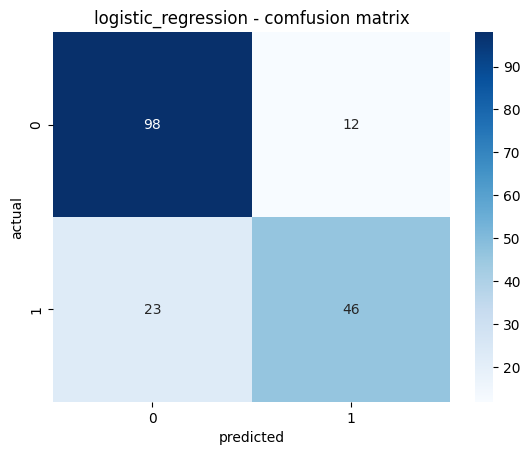

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [70]:
cm=confusion_matrix(y_test,y_pred_log)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("logistic_regression - comfusion matrix")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

print(classification_report(y_test,y_pred_log))